In this notebook, we'll investigate how PCA, MDS and t-SNE dimensionality reduction techniques work on image and text data.

#### **Learning objectives**

By the end of this notebook, you should be able to:
- Understand advanced dimensionality reduction techniques.
- Implement these techniques on image and text data.

#### **Exercise 1: Principal component analysis (PCA)**

1. Apply PCA to the wine dataset and reduce the dimensionality to 2 components. How much variance is explained by the first two principal components?

2. After applying PCA, plot the transformed data points on a scatter plot with different colours for each class. Are the classes well-separated in the reduced dimensionality space?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#### **Load the dataset**

In [3]:
# Load wine dataset
wine = load_wine()

# Separate features and target
X = wine.data
y = wine.target

# Create a DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


#### **Standardise the features**
Why standardise?

The Wine dataset contains features measured on different scales. For example, alcohol content and proline concentration have considerably different numerical ranges.

PCA is sensitive to feature variance. Therefore, standardisation ensures that each feature contributes on a comparable scale.

In [4]:
# Standardise the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

#### **Apply PCA and reduce to two components**

In [5]:
# Initialise PCA with 2 components
pca = PCA(n_components=2)

# Transform the standardised data
X_pca = pca.fit_transform(X_scaled)

In [6]:
# Check the shape of the transformed data
print("Original shape:", X.shape)
print("Transformed shape:", X_pca.shape)


Original shape: (178, 13)
Transformed shape: (178, 2)


#### **Calculate the explained variance**
The explained variance ratio tells us how much of the total information (variance) in the original dataset is captured by each principal component.

In [7]:
# Explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0])
print("PC2:", explained_variance[1])

# Total variance explained
total_variance = explained_variance.sum()

print("Total variance explained:", total_variance)
print("Percentage:", total_variance * 100)

PC1: 0.36198848099926334
PC2: 0.19207490257008938
Total variance explained: 0.5540633835693527
Percentage: 55.40633835693527


__Interpretation:__ The first two principal components explain approximately 55.41% of the total variance in the original 13 features. Therefore, PCA reduces the dataset from 13 dimensions to 2 while retaining approximately 55.41% of its variability.

In [8]:

import matplotlib.pyplot as plt
def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    title_fontsize=14,
    label_fontsize=11,
    remove_spines=True,
    grid=True,
    legend=True,
    xlim=None,
    ylim=None,
):
    """Apply a consistent style to a matplotlib Axes object."""
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=15)

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4, linewidth=0.3, color="gray")
    if legend:
        ax.legend(fontsize=9)

    if remove_spines:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        for spine in ax.spines.values():
            spine.set_linewidth(1.2)

    ax.set_facecolor("whitesmoke")

    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)

    return ax


#### **Visualize the two principal components**

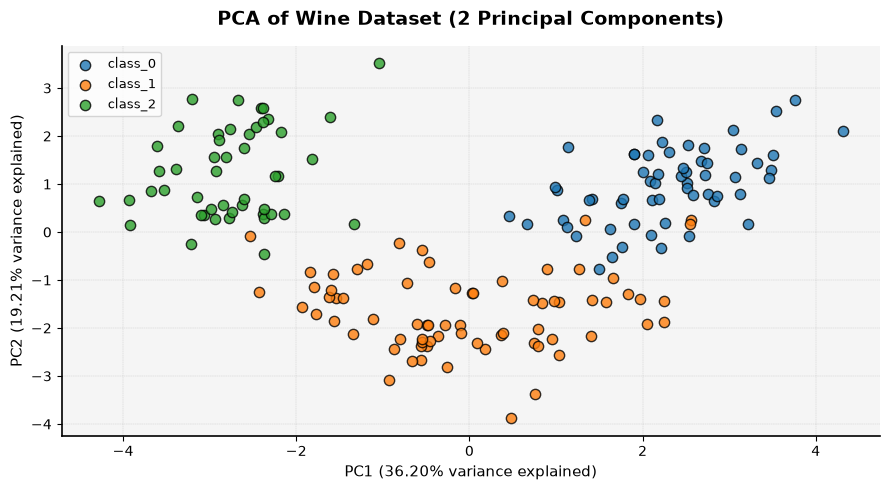

In [9]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Define colours for the three wine classes
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Plot each wine class
for i, color in enumerate(colors):
    ax.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        color=color,
        label=wine.target_names[i],
        alpha=0.8,
        edgecolor='black',
        s=55
    )

# Apply custom plot styling
style_plot(
    ax,
    title="PCA of Wine Dataset (2 Principal Components)",
    xlabel=f"PC1 ({explained_variance[0]*100:.2f}% variance explained)",
    ylabel=f"PC2 ({explained_variance[1]*100:.2f}% variance explained)",
    legend=True
)

plt.tight_layout()
plt.show()

The three wine classes show a reasonable degree of separation in the two-dimensional PCA space.
- Class 0: Generally forms a distinct cluster, separated from the other two classes.
- Class 1: Forms a cluster that is relatively distinguishable but overlaps somewhat with Class 2.
- Class 2: Shows some separation from Class 0 but overlaps with Class 1.

This suggests that the first two principal components capture meaningful variation that helps distinguish the three wine classes.

__Conclusion:__

PCA successfully reduced the Wine dataset from 13 features to 2 principal components. The first two components explain approximately 55.41% of the total variance. The scatter plot reveals reasonable separation among the three wine classes, although some overlap exists between Classes 1 and 2. This demonstrates that PCA can reduce dimensionality while preserving useful information for visualising patterns and potential class differences in high-dimensional data.

#### **Exercise 2: Multi-dimensional scaling (MDS)**
Apply MDS to the wine dataset and reduce the dimensionality to 2 components. What is the stress value of the MDS transformation?
Plot the transformed data points on a scatter plot with different colors for each class. Do you observe any clusters or patterns in the reduced dimensionality space?

The objective is to apply **Multidimensional Scaling (MDS)** to the Wine dataset, reduce its 13 features to 2 dimensions, and examine the resulting clusters and patterns.

**What is Multidimensional Scaling (MDS)?**

Multidimensional Scaling (MDS) is an unsupervised dimensionality reduction technique that attempts to represent high-dimensional observations in a lower-dimensional space while preserving the distances (dissimilarities) between observations.

Unlike PCA, which identifies directions of maximum variance, MDS focuses on preserving pairwise distances between data points.

__Key concept: Stress__

Stress measures how well the distances in the reduced-dimensional space represent the original distances.
- Lower stress indicates better preservation of distances.
- Higher stress indicates greater distortion.
- A stress value of zero indicates perfect preservation of the original distances.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import MDS

#### **Load and standardise the Wine dataset**

In [11]:
# Load wine dataset
wine = load_wine()

# Separate features and target
X = wine.data
y = wine.target

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check dimensions
print("Original shape:", X.shape)
print("Standardised shape:", X_scaled.shape)

Original shape: (178, 13)
Standardised shape: (178, 13)


Standardisation is important because MDS relies on distances between observations. Features with larger numerical scales could otherwise dominate the distance calculations.

#### **Apply MDS and reduce to two dimensions**
We initialise MDS with two components because our objective is to represent the observations in a two-dimensional space.

In [15]:
# Initialise MDS
mds = MDS(
    n_components=2,
    metric_mds=True,
    metric="euclidean",
    random_state=42,
    normalized_stress=True,
    init="classical_mds"
)

# Fit and transform the data
X_mds = mds.fit_transform(X_scaled)

# Check transformed dimensions
print("Original shape:", X_scaled.shape)
print("Transformed shape:", X_mds.shape)

Original shape: (178, 13)
Transformed shape: (178, 2)


In [16]:
# Retrieve the stress value
stress = mds.stress_

print("MDS Stress Value:", stress)

MDS Stress Value: 0.23095084816146094


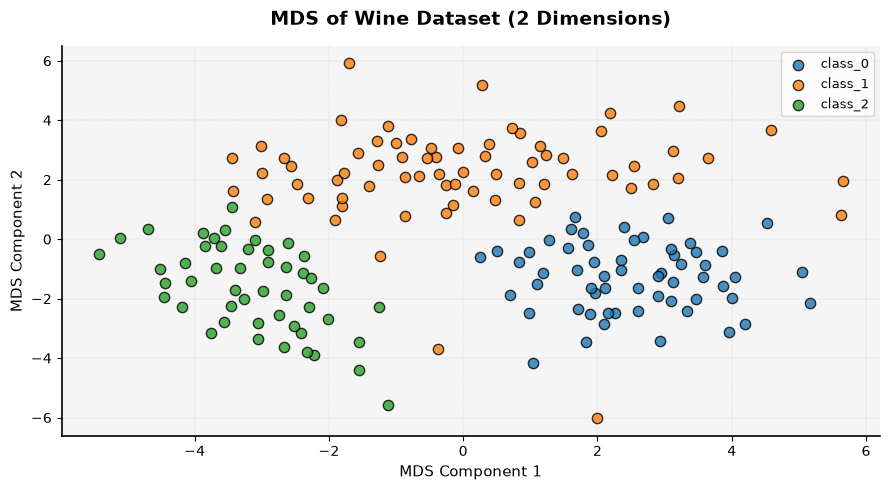

In [18]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Define colours for the three classes
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Plot each wine class
for i, color in enumerate(colors):
    ax.scatter(
        X_mds[y == i, 0],
        X_mds[y == i, 1],
        color=color,
        label=wine.target_names[i],
        alpha=0.8,
        edgecolor='black',
        s=55
    )

# Apply custom styling
style_plot(
    ax,
    title="MDS of Wine Dataset (2 Dimensions)",
    xlabel="MDS Component 1",
    ylabel="MDS Component 2",
    legend=True
)

plt.tight_layout()
plt.show()

#### **Interpretation of the MDS Scatter Plot**

The MDS visualisation reveals a relatively clear separation among the three wine classes in the two-dimensional space.

- Class 0 (Blue): Forms a cluster predominantly in the lower-right region of the plot, indicating that observations belonging to this class share relatively similar characteristics.
- Class 1 (Orange): Occupies mainly the upper-central region, with a few observations extending towards the lower region. This suggests some variation within the class.
- Class 2 (Green): Forms a relatively compact cluster in the lower-left region, suggesting similarities among observations within this class.

Cluster separation: The three classes exhibit noticeable clustering patterns, with relatively little overlap. This suggests that MDS has captured meaningful dissimilarity structures that help distinguish the wine classes in two dimensions.

#### **Conclusion**

MDS successfully reduced the Wine dataset from 13 dimensions to 2 while revealing meaningful clustering patterns among the three wine classes. Class 0 and Class 2 form relatively distinct clusters, while Class 1 occupies the upper-central region with a few scattered observations. Overall, the visualisation suggests that the distance-based representation preserves useful structural information from the original dataset.

Important qualification: Visual separation alone does not establish how accurately the original distances were preserved. The MDS stress value should also be considered when evaluating the quality of the dimensionality reduction.

#### **Exercise 3: t-distributed Stochastic Neighbour Embedding (t-SNE)**

1. Apply t-SNE to the wine dataset and reduce the dimensionality to 2 components. How long does it take to compute the t-SNE embedding?

2. Plot the transformed data points on a scatter plot with different colors for each class. What do you observe about the clusters in the reduced dimensionality space?

#### **Exercise 3: t-Distributed Stochastic Neighbour Embedding (t-SNE) – Wine Dataset**

The objective is to apply t-distributed Stochastic Neighbour Embedding (t-SNE) to the Wine dataset, reduce its dimensionality from 13 features to 2 components, measure the computation time, and examine the clustering patterns.

#### **1. What is t-SNE?**

t-SNE is an unsupervised, nonlinear dimensionality reduction technique used primarily for visualising high-dimensional datasets.

It attempts to preserve the local neighbourhood relationships between observations. In other words, observations that are similar in the original feature space are encouraged to remain close together in the lower-dimensional representation.

__Key characteristics:__

- Preserves local similarities between observations.
- Captures nonlinear relationships.
- Useful for visualising clusters in high-dimensional datasets.
- Unlike PCA, it does not produce components that directly explain a percentage of the original variance.

#### **Step 1: Import the necessary libraries**

```


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

#### **Step 2: Load and standardise the Wine dataset**

Standardisation is important because t-SNE uses distances and similarities to identify neighbouring observations. Features with larger numerical scales could otherwise dominate these calculations.

In [20]:
# Load wine dataset
wine = load_wine()

# Separate features and target
X = wine.data
y = wine.target

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check dimensions
print("Original shape:", X.shape)
print("Standardised shape:", X_scaled.shape)

Original shape: (178, 13)
Standardised shape: (178, 13)


#### **Step 3: Apply t-SNE and measure computation time**

Understanding the parameters:

| Parameter              | Explanation                                                            |
| ---------------------- | ---------------------------------------------------------------------- |
| `n_components=2`       | Reduces the dataset to two dimensions.                                 |
| `perplexity=30`        | Controls the effective number of neighbouring observations considered. |
| `random_state=42`      | Ensures reproducibility.                                               |
| `init='pca'`           | Uses PCA to initialise the embedding.                                  |
| `learning_rate='auto'` | Automatically determines the learning rate.                            |


In [22]:
# Initialise t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
    learning_rate='auto'
)

# Record start time
start_time = time.perf_counter()

# Fit and transform the data
X_tsne = tsne.fit_transform(X_scaled)

# Record end time
end_time = time.perf_counter()

# Calculate computation time
computation_time = end_time - start_time

# Display results
print("Original shape:", X_scaled.shape)
print("Transformed shape:", X_tsne.shape)
print(f"Computation time: {computation_time:.4f} seconds")

Original shape: (178, 13)
Transformed shape: (178, 2)
Computation time: 4.4330 seconds


#### **Step 4: Visualise the two-dimensional t-SNE embedding**

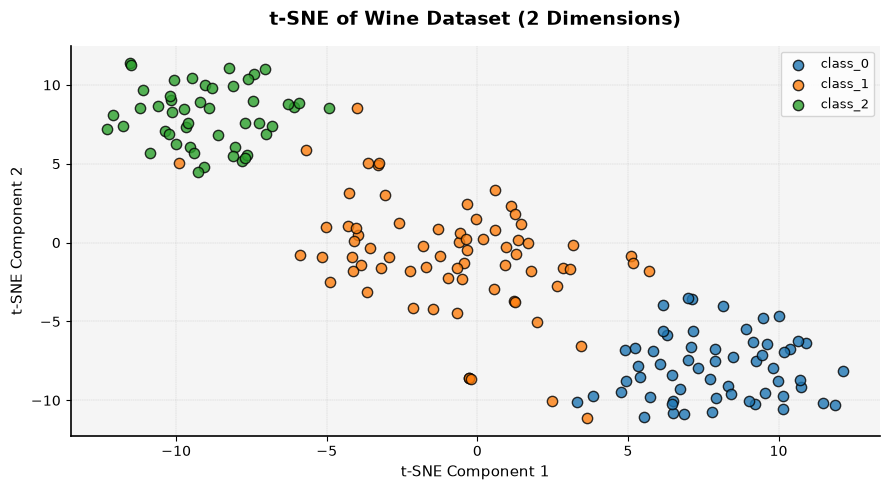

In [23]:
# Create figure and axes
fig, ax = plt.subplots(figsize=(9, 5))

# Define colours for the three classes
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Plot each wine class
for i, color in enumerate(colors):
    ax.scatter(
        X_tsne[y == i, 0],
        X_tsne[y == i, 1],
        color=color,
        label=wine.target_names[i],
        alpha=0.8,
        edgecolor='black',
        s=55
    )

# Apply custom styling
style_plot(
    ax,
    title="t-SNE of Wine Dataset (2 Dimensions)",
    xlabel="t-SNE Component 1",
    ylabel="t-SNE Component 2",
    legend=True
)

plt.tight_layout()
plt.show()

#### **Interpretation of the t-SNE Scatter Plot**

The t-SNE visualisation reveals a clear clustering structure and nonlinear separation among the three wine classes in the two-dimensional embedding.

- Class 0 (Blue): Forms a relatively compact cluster in the lower-right region, indicating strong local similarities among observations within this class.
- Class 1 (Orange): Occupies the central region of the plot, forming a distinct cluster between the other two classes. Its wider spread suggests greater variation in the positions of its observations.
- Class 2 (Green): Forms a relatively compact cluster in the upper-left region, showing clear separation from the other two classes.

Cluster separation: The three classes demonstrate strong visual separation, with Class 0 and Class 2 particularly well isolated. Class 1 occupies the central region but remains distinguishable as a separate cluster.

#### **Conclusion**

t-SNE successfully reveals the underlying clustering structure of the Wine dataset by reducing its 13 features to two dimensions. The visualisation shows distinct clusters corresponding to the three wine classes, suggesting that the dataset contains meaningful nonlinear and local neighbourhood relationships. Compared with PCA and MDS, t-SNE provides a particularly clear visual separation of the classes in this embedding.

Important qualification: Although t-SNE produces visually distinct clusters, this does not necessarily mean it preserves global distances or that the classes are perfectly separable in the original feature space. Its primary objective is to preserve local neighbourhood similarities.